### **1. Introduction to Gaussian Processes:**

Gaussian processes (GPs) belong to the class of non-parametric models. Before we move on to introducing GPs in more detail, let's recap the difference between parametric vs. non-parametric models. The number of parameters, which the former estimate during the training process, does not depend on the sample size of the data. Example for a parametric approach is Linear Regression, which estimates the beta coefficients associated with the predictor variables. By contrast, in non-parametric models the number of parameters to estimate grows with the sample size of the data. For instance, in the case of GPs, the number of parameters to estimate is effectively infinite, as GPs model functions across their entire input space. Another distinctive characteristic is that parametric approaches make assumptions about the functional relationship between the input predictors and the target variable, e.g., Linear Regression assumes linear dependence between the inputs and the outputs. In comparison to this, GPs do not assume a specific functional form, and can thus model arbirtrary nonlinear dependencies. <br> 

GPs in a nutshell:<br>

- GPs represent stochastic processes, i.e, a collection over random variables.
- put slightly different, GPs describe a distribution over functions $f(X)$ with continuous domain, which are evaluated at specific locations $x$ from $X$. 
- we approximate GPs with the multivariate Gaussian distribtuion, which makes use of two functions, i.e., the mean function $mu(X)$, and the covariance function $k(X,X')$:<br> $GP(X)$~$N(mu(X),k(X,X'))$<br>

- so that you better understand how we get from Gaussian scalars to GPs, consider the following:<br>
    - if we have a single vector $x$ of a specific dimensionality, then for the function value of $f(x)$ we use the Gaussian scalar:<br> $f(x)$~$N(µ(x), σ2(x))$, where $µ$ is a scalar representing the mean of $x$, and $σ2$ is a scalar representing the variance of $x$<br>

    - if we have two vectors $x1$ and $x2$, then for the value of the joint function at these two locations we use the bivariate (multivariate) Gaussian distribution:<br> $f(x1,x2)$~$N(mu(x1,x2), Σ(x1,x2))$, where $mu$ is the mean function, and $Σ$ is the covariance between the two vectors.<br>

    - for the joint distribution of the function $f(X)$ at all possible locations $X$, we use Gaussian Processses:<br> $f(x)$~$N(mu(X), k(X,X'))$, where $k(X,X')$ is a kernel function, which computes the covariance matrix, i.e., the $Σ$ for each pair of samples in $X$.<br>

- The kernel function in GPs facilitate the modelling of arbitrary nonlinear patterns. Thus, the kernel function is one of the central components of GPs. The kernel produces the covariance matrix containing the covariance values/similarity values between each pair of samples in $X$. Thus, GPs produce a distribution of estimates per data sample input based on its proximity to all other samples in $X$.<br>

- Selecting a specific kernel function, e.g., RBF kernel, Matern kernel, etc., amounts to setting a prior on the modeling process. Sampling values from your GP prior amounts to estimating a marginal distribution. The latter describes the joint probability of the concrete set of random variables/data samples/vectors $x$ from $X$ occuring while marginalizing out other variables. The marginal distribution is different from the conditional distribution in that no conditioning on other variable subsets is performed when estimating the output of the distribution. The RBF kernel, which is a common choice for a GP prior, is defined in the following way:<br>

    -    $k(X,X') =exp(-\frac{dist(X,X')²}{2l²})$, where $l$ is the length-scale parameter, which determines how quickly the similarity/covariance between two inputs decays with increasing distance. <br>

Now, let's take a look at how samples from RBF kernel prior look like:

In [1]:
import scipy
import numpy as np
import matplotlib.pyplot as plt

#Source: https://peterroelants.github.io/posts/gaussian-process-tutorial/

#Computes the covariance matrix as a square matrix of distances between each pair of rows:
def exponentiated_quadratic(xa, xb,length_scale):
    """Exponentiated quadratic/RBF kernel"""
    # L2 distance (Squared Euclidian)
    sq_norm = (-1 * scipy.spatial.distance.cdist(xa, xb, 'sqeuclidean'))/(2*length_scale)
    return np.exp(sq_norm)

Shape of Inputs X:  (100, 2)
Shape of Covariance Matrix:  (100, 100)
Shape of Samples from GP with RBF Kernel:  (5, 100)


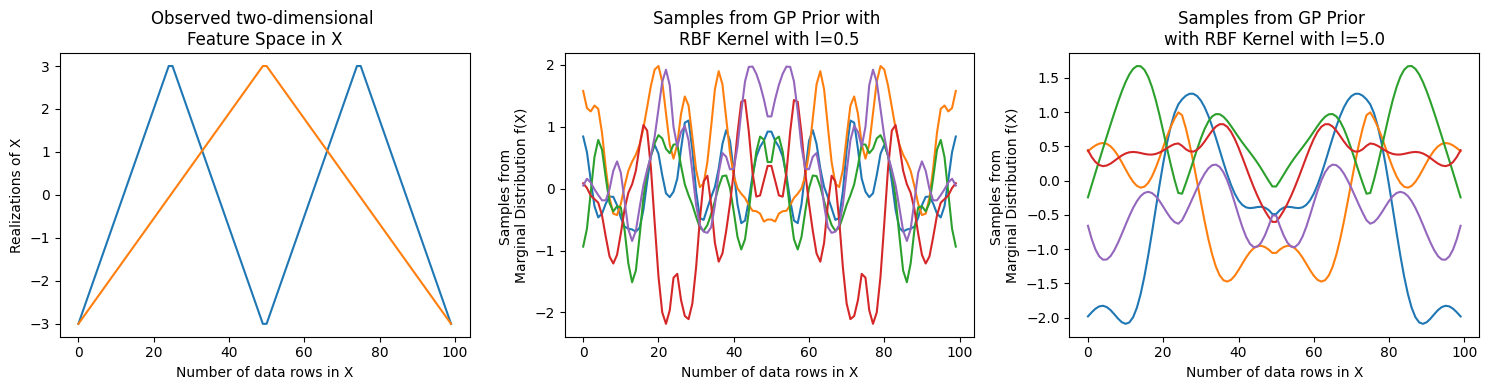

In [2]:
#We simulate a 2-dimensional feature space X having 100 data samples:
xlim=(-3,3)
X=np.zeros(shape=(100,2))
X[:,0]=np.concatenate([np.linspace(*xlim, 25),np.linspace(*(3,-3), 25)]*2)
X[:,1]=np.concatenate([np.linspace(*xlim, 50),np.linspace(*(3,-3), 50)])


print('Shape of Inputs X: ',X.shape)
Σ = exponentiated_quadratic(X, X,0.5)
print('Shape of Covariance Matrix: ',Σ.shape)

nb_of_samples = X.shape[0] 
number_target_samples = 5

ys = np.random.multivariate_normal(
    mean=np.zeros(nb_of_samples), cov=Σ, 
    size=number_target_samples)

print('Shape of Samples from GP with RBF Kernel: ',ys.shape)
fig, ax=plt.subplots(nrows=1,ncols=3,figsize=(15,4))
ax[0].plot(X)
ax[0].set_xlabel('Number of data rows in X')
ax[0].set_ylabel('Realizations of X')
ax[0].set_title('Observed two-dimensional \nFeature Space in X')

ax[1].plot(ys.T)
ax[1].set_xlabel('Number of data rows in X')
ax[1].set_ylabel('Samples from \nMarginal Distribution f(X)')
ax[1].set_title('Samples from GP Prior with \nRBF Kernel with l=0.5')


ax[2].plot(np.random.multivariate_normal(
    mean=np.zeros(nb_of_samples), cov=exponentiated_quadratic(X, X,5.0), 
    size=number_target_samples).T)
ax[2].set_xlabel('Number of data rows in X')
ax[2].set_ylabel('Samples from \nMarginal Distribution f(X)')
ax[2].set_title('Samples from GP Prior \nwith RBF Kernel with l=5.0')

fig.tight_layout()

plt.show()
plt.close()


As you can see, the samples from the GP prior represent nonlinear variations of the input feature space. Larger length scale leads to points further apart stil being considered similar, whereas smaller length scale makes points further apart more dissimilar. For this reason, in the above plots increasing the values of the length-scale parameter results into a decrease in the local variations.<br>

 While so far we have covered what is meant by sampling from the prior of GPs, in your seminar project, you will be dealing with the estimation of the conditional distribution p(y2|X2,y1,X1), where y2 and X2 are new data samples, and y1 and X1 are data samples seen during the model fitting process. Estimating the conditional distribution amounts to estimating the so-called posterior. You can check out the example for sampling from the posterior under: https://peterroelants.github.io/posts/gaussian-process-tutorial/. In the example provided under the link, the author samples from the posterior distribution without estimating the $\theta$ hyperparameters of the GP, which influence, e.g., the magnitude of the length-scale of kernel function. 

In [102]:
from sklearn.model_selection import train_test_split
import sklearn
from sklearn.gaussian_process import GaussianProcessRegressor

#Simulate a synthetic target and split into train and test set:
y=np.sin(X@np.random.normal(size=2))
X1,X2,y1,y2=train_test_split(X,y,test_size=0.3,random_state=523)

gp=GaussianProcessRegressor(kernel=sklearn.gaussian_process.kernels.RBF(length_scale=1.0,length_scale_bounds=(0.5, 100.0)))
print('GP Length-scale before model fitting: ',gp.kernel.length_scale)
gp.fit(X1,y1)
print('GP Length-scale after model fitting: ',gp.kernel_.length_scale)



GP Length-scale before model fitting:  1.0
GP Length-scale after model fitting:  2.4685989397349895


The estimation of these hyperparameters takes place during the model fitting process, which aims at minimizing the negative of the marginal log-likelihood. The latter represents the likelihood of the observed data given the model parameters. While you should know that these hyperparameters get updated during the modeling process, you do not need to know how exactly the updates are computed, as this always happens on the background of the GP.fit() method.<br>


In the examples we have covered so far we sampled data from GPs with a specific kernel function. Now, let's imagine we could also design komplex kernels, which consist of the sum of several functions. The choice of which kernels to include in our complex kernel formulation should ideally be the result of hyperparameter tuning. Libraries like sklearn offer a rather standard set of options for the kernel functions to be explored during hyperparameter optimization. A further limitation of GPregressors in sklearn is the lacking integration to deep learning libraries, e.g. pytorch.

### **2. Regression using Neural GPs with GPytroch**

Neural GPs provide us with the flexibility to learn the parameters of our distribution with the trainable variables (weights) of neural networks. The main advantages of GPytorch over other libraries (e.g., sklearn) are the following: <br>

- GPytorch provides integration to neural pytorch layers, e.g., MLP, Conv, RNN. These can be used as latent feature extractors, which provide inputs to the mean and covariance functions of GPytroch. In this way, instead of computing the mean and the covariance directly from the observed data, we can first extract deep latent features, capturing complex relationships in our data, based on which we would estimate the parameters of the GP. <br>

- higher flexibility in model implementation concerning, e.g., the capacity of our probabilistic models. With GPytroch we can learn a single weight or a number of weights equal to the amount of predictor features for the estimation of the lengthscale of the selected kernel functions. Additionally, we can easily encode a mixture of GPs with a specific mean and kernel function to further increase the capacity of our neural distributional model. Each mixture component could receive the inputs from different latent feature extractors, which would encourage each distributional component to focus on slightly different patterns in our data.<br>

In [103]:
import gpytorch
import torch

In [108]:
#Let's simulate some synthetic data:
number_iid_samples=500
number_predictors=9

X=torch.randn(number_iid_samples,number_predictors)
y=torch.nn.ReLU()(X@torch.rand(number_predictors))

X=(X-X.mean(axis=0))/X.std(axis=0)
y=(y-y.mean(axis=0))/y.std(axis=0)

print('Shape if predictor inputs: ',X.shape)
print('Shape of outputs: ',y.shape)

Shape if predictor inputs:  torch.Size([500, 9])
Shape of outputs:  torch.Size([500])


##### **Exact GPs for the Forecasting of a single continuous Variable**<br>
In GPytorch, we could use either exact GPs or approximate GPs to model the distribution of our data. While exact GPs are more accurate, approximate GPs are more efficient. In this notebook, we will cover exact GPs as accuracy is for now our main goal. Also, GPytorch provides examples for accelerating exact GPs (https://github.com/cornellius-gp/gpytorch/tree/v1.12/examples/02_Scalable_Exact_GPs). 

In [109]:
from gpytorch.means import LinearMean
from gpytorch.kernels import RBFKernel,ScaleKernel
from gpytorch.distributions import MultivariateNormal

First, let's initialize the covariance/kernel module and the mean module of a GP with GPytroch:

In [110]:
#Initialize the covariance module and the mean module in GPytorch:
#RBF Kernel with lenghtscale trainable parameters per each predictor variable:
covar_module = gpytorch.kernels.RBFKernel(ard_num_dims=X.shape[1])
covar = covar_module(X)
mean_module = LinearMean(input_size=X.shape[1])
mean=mean_module(X)

#Let's examine the output shapes:
print('Shape of covariance matrix: ',covar.shape)
print('Shape of means: ',mean.shape)
gp_process_output=gpytorch.distributions.MultivariateNormal(mean, covar)
print('Shape of Multivariate Output Distributions: ',gp_process_output.sample().shape)

Shape of covariance matrix:  torch.Size([500, 500])
Shape of means:  torch.Size([500])
Shape of Multivariate Output Distributions:  torch.Size([500])


In [107]:
print('Shape of trainable Variables of Mean Module: ',list(mean_module.parameters())[0].shape)
print('Shape of trainable Variables of Kernel Module: ',list(mean_module.parameters())[0].shape)

Shape of trainable Variables of Mean Module:  torch.Size([9, 1])
Shape of trainable Variables of Kernel Module:  torch.Size([9, 1])


Next, we will implement a deep GP-based model, which consist of both deterministic and probabilistic components: https://docs.gpytorch.ai/en/v1.13/examples/02_Scalable_Exact_GPs/Simple_GP_Regression_With_LOVE_Fast_Variances_and_Sampling.html <br>

*Latent Feature Extractor*

In [ ]:
class LatentFeatureExtractor(torch.nn.Module):
    def __init__(self, 
                 input_dim:int,
                 latent_dimension:int,
                 num_mixtures:int,
                 num_layers:int,
                 dropout_rate:float,
                 skip_connections:bool,
                 normalize_latent_outputs:bool):
        
        '''
        Extracts (nonlinear) latent representation from input variables fed to a deep GP model. The LatentFeatureExtractor
        represents the deterministic part of the whole network.

        
        Parameters:
        -----------
        input_dim: int
            The number of input features.

        latent_dimension:int
            The number of hidden units each mixture component of the neural GP receives.
        
        num_mixtures:int
            Number of mixture components.
        
        num_layers:int
            Number of hidden layers.

        dropout_rate:float
            The percentage of hidden units to drop out during the forward pass.
        
        skip_connections:bool
            Whether to apply skip connections after each hidden layer.
        
        normalize_latent_outputs:bool
            Whether to normalize the latent representation produced by each hidden layer.
        

        Attributes:
        (in addition to the Parameters)
        -----------
        latent_output_dim: int
            An attribute, which is computed based on the product of latent_dimension with num_mixtures. It determines
            the amount of hidden units, which act as inputs to every mixture component of the neural GP.

        latent_layers: torch.nn.ModuleList
            The torch module list containing the nonlinear layers.

        norm_latent_layers: torch.nn.ModuleList
            The torch module list containing the normalization layers, applied in the forward pass after each hidden layer.

        
        Methods:
        ---------
        forward: 
            Performs the forward pass with the latent feature extractor.   

        '''
        
        
        super(LatentFeatureExtractor, self).__init__()
        self.input_dim=input_dim
        self.num_layers=num_layers
        self.dropout_rate=dropout_rate
        self.skip_connections=skip_connections
        self.normalize_latent_outputs=normalize_latent_outputs

        self.latent_dimension=latent_dimension
        self.num_mixtures=num_mixtures
        self.latent_output_dim=num_mixtures*latent_dimension
        
        #Put all trainable variables in a ModuleList, otherwise pytroch will not update the weights
        #in the latent feature extractor:
        #Latent feature extractors:
        self.latent_layers=torch.nn.ModuleList([torch.nn.Linear(input_dim, self.latent_output_dim) if nr_layer==0 else torch.nn.Linear(self.latent_output_dim, self.latent_output_dim) for nr_layer in range(0,self.num_layers+1)])
        #Latent normalization layers:
        if self.normalize_latent_outputs==True:
            self.norm_latent_layers=torch.nn.ModuleList([torch.nn.LayerNorm(self.latent_output_dim) for nr_layer in range(0,self.num_layers+1)])# if nr_layer==0 else torch.nn.LayerNorm(self.latent_output_dim) for nr_layer in range(0,self.num_layers+1)])
        


    def forward(self,x):
        for nr_layer in range(0,self.num_layers+1):
            #Apply linear projection to a latent dimension:
            latent_output=(self.latent_layers[nr_layer](x) if nr_layer==0 else self.latent_layers[nr_layer](previous_latent_output))
            
            #Apply nonlinear transformations followed with dropouts only to intermediate layers (excluding last linear projection layer):
            if nr_layer!=self.num_layers:
                #Apply nonlinear transformation:
                latent_output=torch.nn.ReLU()(latent_output)
                
                if self.dropout_rate!=0.0:
                    latent_output=torch.nn.Dropout(self.dropout_rate)(latent_output)

                #Apply skipconnection if current layer in [1,self.num_layers-1]
                if nr_layer!=0:
                    if self.skip_connections==True:
                        latent_output=latent_output+previous_latent_output

                
            #Check if the latent feature extractor makes use of normalization layers:            
            if self.normalize_latent_outputs==True:
                latent_output=self.norm_latent_layers[nr_layer](latent_output)

            previous_latent_output=latent_output
        
        #TO-DO:
        #When you set the self.num_mixtures parameter to anything higher than 1,
        #then here you would have to split the torch Tensor along the last dimension to obtain
        #the latent features for each GP mixture, and encode and if-else condition what the output values
        #of the forward method should be based on self.num_mixtures
        return latent_output


*Exact GP Regressor*

In [ ]:
class Exact_GPRegressionModel(gpytorch.models.ExactGP):
    def __init__(self, train_x, #train_y, 
                 likelihood,kernel_type,
                 latent_dimension,num_mixtures,num_layers,
                 dropout_rate,skip_connections,normalize_latent_outputs):
        
        super(Exact_GPRegressionModel, self).__init__(None,None,likelihood)
        self.num_mixtures=num_mixtures

        #Initialize latent feature extractor:
        self.feature_extractor = LatentFeatureExtractor(input_dim=train_x.shape[-1],latent_dimension=latent_dimension,
                                            
                                                        num_mixtures=self.num_mixtures,dropout_rate=dropout_rate,
                                                        num_layers=num_layers,skip_connections=skip_connections,
                                                        normalize_latent_outputs=normalize_latent_outputs)
        
        #Initialize mean and covariance modules:
        #TO-DO: encode if-else condition for multiple GP mixtures using the same type of mean and kernel functions.
        #The list of mean and covariance modules should be wrapped in torch.nn.ModuleList as otherwise torch would not
        #compute gradients w.r.t. the trainable parameters of mixture components.
        self.mean_module = gpytorch.means.LinearMean(input_size=latent_dimension)
        self.covar_module=self.get_kernel(kernel_type=kernel_type,latent_dimension=latent_dimension)
        
    
    def get_kernel(self,kernel_type,latent_dimension):
        
        if type(kernel_type)==str:
                covar_module = (gpytorch.kernels.RBFKernel(ard_num_dims=latent_dimension) if kernel_type=='RBF' else 
                                     (gpytorch.kernels.MaternKernel(ard_num_dims=latent_dimension) if kernel_type=='Matern' else 
                                      (gpytorch.kernels.SpectralMixtureKernel(ard_num_dims=latent_dimension,num_mixtures=1) if kernel_type=='Spectral' else gpytorch.kernels.LinearKernel(ard_num_dims=latent_dimension))))
        else:#list of kernels:
            for idx in range(0,len(kernel_type)):
                if idx==0:
                    covar_module = (gpytorch.kernels.RBFKernel(ard_num_dims=latent_dimension) if kernel_type[idx]=='RBF' else 
                                    (gpytorch.kernels.MaternKernel(ard_num_dims=latent_dimension) if kernel_type[idx]=='Matern' else 
                                     (gpytorch.kernels.SpectralMixtureKernel(ard_num_dims=latent_dimension,num_mixtures=1) if kernel_type[idx]=='Spectral' else gpytorch.kernels.LinearKernel(ard_num_dims=latent_dimension))))
                else:
                    covar_module = covar_module+(gpytorch.kernels.RBFKernel(ard_num_dims=latent_dimension) if kernel_type[idx]=='RBF' else 
                                    (gpytorch.kernels.MaternKernel(ard_num_dims=latent_dimension) if kernel_type[idx]=='Matern' else 
                                     (gpytorch.kernels.SpectralMixtureKernel(ard_num_dims=latent_dimension,num_mixtures=1) if kernel_type[idx]=='Spectral' else gpytorch.kernels.LinearKernel(ard_num_dims=latent_dimension))))
        
        return ScaleKernel(covar_module)
    
    def forward(self, x):
        projected_x = self.feature_extractor(x)
        
        #TO-DO: adjust the forward pass for multiple mixture components
        #if self.num_mixtures==1:
        mean_x = self.mean_module(projected_x)
        
        covar_x = self.covar_module(projected_x)
        
        return gpytorch.distributions.MultivariateNormal(mean_x, covar_x)
        #here comes the else part: self.num_mixtures>1

In [85]:
#initialize the model and the device to train the neural GP on:
likelihood = gpytorch.likelihoods.GaussianLikelihood()
num_mixtures=1
model = Exact_GPRegressionModel(train_x=X, 
                                likelihood=likelihood,
                                #Hyperparameters related to deep latent feature extractor:
                                latent_dimension=200,num_layers=3,dropout_rate=0.0,
                                skip_connections=False,normalize_latent_outputs=True,
                                #hyperparameters related to probabilistic forecasts:
                                num_mixtures=num_mixtures,kernel_type='RBF_Matern_Linear'.split('_'))

if torch.cuda.is_available():
    model = model.cuda()
    likelihood = likelihood.cuda()
    X=X.to(device='cuda')
    y=y.to(device='cuda')

In [86]:
#Once the dataset is put on gpu/cpu, then split the data into mini-batches
#Given that you benefit the most from gpytorch if you train the models on gpu,
#you cannot feed the whole data to your models, as you will run out of memory,
#in such cases mini-batch gradient descent is very useful!
#  
from torch.utils.data import TensorDataset, DataLoader
train_dataset = TensorDataset(X, y)
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)

In [87]:
#Train the deep GP time series model:
model.train()
likelihood.train()
optimizer = torch.optim.Adam(model.parameters(), lr=0.005) 
mll = gpytorch.mlls.ExactMarginalLogLikelihood(likelihood, model)


training_iterations = 40

for i in range(0,training_iterations):
    epoch_loss=[]
    
    for batch_idx,(train_x,train_y) in enumerate(train_loader):
        
        #necessary in the case of exact GPs:
        model.set_train_data(inputs=train_x,targets=train_y,strict=False)
        
        with gpytorch.settings.fast_pred_samples():    
            optimizer.zero_grad()
            #Perform forward pass:
            output = model(train_x)
        
            current_loss = -mll(output, train_y)
            loss=current_loss.mean()
            
            #Perform the backward pass:
            loss.backward()
            optimizer.step()
            
            epoch_loss.append(loss.item())

    print('Training Iteration/Epoch : ',i,', Loss Value: ',np.mean(epoch_loss))

Training Iteration/Epoch :  0 , Loss Value:  1.8404332995414734
Training Iteration/Epoch :  1 , Loss Value:  0.9918991148471832
Training Iteration/Epoch :  2 , Loss Value:  0.7363064169883728
Training Iteration/Epoch :  3 , Loss Value:  0.7013843774795532
Training Iteration/Epoch :  4 , Loss Value:  0.6746829688549042
Training Iteration/Epoch :  5 , Loss Value:  0.6504591941833496
Training Iteration/Epoch :  6 , Loss Value:  0.6269686758518219
Training Iteration/Epoch :  7 , Loss Value:  0.603994345664978
Training Iteration/Epoch :  8 , Loss Value:  0.5812015235424042
Training Iteration/Epoch :  9 , Loss Value:  0.5585668087005615
Training Iteration/Epoch :  10 , Loss Value:  0.5361312508583069
Training Iteration/Epoch :  11 , Loss Value:  0.5132893562316895
Training Iteration/Epoch :  12 , Loss Value:  0.4901104837656021
Training Iteration/Epoch :  13 , Loss Value:  0.46715712547302246
Training Iteration/Epoch :  14 , Loss Value:  0.44402462244033813
Training Iteration/Epoch :  15 , L

In [88]:
model.eval()

#Estimate the distribution on the whole dataset:
output=model(X)

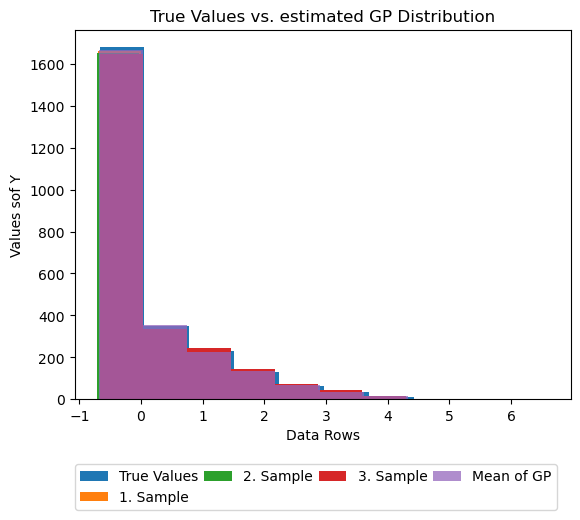

In [89]:
plt.hist(y.cpu(),label='True Values')
plt.hist(output.sample().cpu(),label='1. Sample')
plt.hist(output.sample().cpu(),label='2. Sample')
plt.hist(output.sample().cpu(),label='3. Sample')
plt.hist(output.mean.cpu().detach().numpy(),label='Mean of GP',alpha=0.75)
plt.title('True Values vs. estimated GP Distribution')
plt.xlabel('Data Rows')
plt.ylabel('Values sof Y')
plt.legend(ncols=4,mode='expand',loc=[0.0,-0.30])

### **3. Time Series Forecasting with neural GPs**

Implementation-wise, neural GPs for time series bear a lot of similarities to the i.i.d. case with the exception of the kernel function, and the latent feature extractor. Ideally, the latter should account for the temporal components in the data. You could start with integrating the following functionalities, which focus on modeling different temporal patterns:<br>
- Patching from PatchTST with nonlinear transformations instead of self-attention: https://arxiv.org/pdf/2211.14730
- Temporal and channel mixing layers from TSMixer and MTS Mixer (the version applying factorization): https://arxiv.org/pdf/2303.06053, https://arxiv.org/pdf/2302.04501<br>

Given that neural GPs for time series would require more computational ressources that for i.i.d. data, you could first tune the latent feature extractor module, which produces deterministic outputs. Once the architecture of the latent feature extractor is set, you can move on to applying the probabilisitc GP on top of it. For demonstration purposes of how neural GPs would be applied to temporal data, first, let's simulate some synthetic time series, and examine the output from a SpectralMixtureKernel.

In [90]:
import torch
import gpytorch

number_samples=1808
seq_len=96
number_predictors=20

X=torch.randn(number_samples,seq_len,number_predictors)
y=torch.nn.ReLU()(X@torch.rand(number_predictors))+torch.sin(X@torch.rand(number_predictors))

X=(X-X.mean(axis=0))/X.std(axis=0)
y=(y-y.mean(axis=0))/y.std(axis=0)

print('Shape if predictor inputs: ',X.shape)
print('Shape of outputs: ',y.shape)

Shape if predictor inputs:  torch.Size([1808, 96, 20])
Shape of outputs:  torch.Size([1808, 96])


In [91]:
covar_module = gpytorch.kernels.SpectralMixtureKernel(ard_num_dims=X.shape[-1],num_mixtures=1)
covar = covar_module(X)
mean_module = LinearMean(input_size=X.shape[-1])
mean=mean_module(X)

#Let's examine the output shapes:
print('Shape of covariance matrix: ',covar.shape)
print('Shape of means: ',mean.shape)

Shape of covariance matrix:  torch.Size([1808, 96, 96])
Shape of means:  torch.Size([1808, 96])


The kernel function is applied along the temporal dimension (along the 96 timesteps in each input sequence). Thus, despite the fact that GPytorch was not initially designed for time series data, provided the input data is transformed into the shape (samples,sequence length,number of time series), then GPytorch's kernel function will compute the similarities between the timesteps of every sequence. This facilitates the application of GPytorch to temporal data in addition to i.i.d. data. Using kernel functions, which account for temporal dependencies such as SpectralMixtureKernel, CosineKernel etc., are meaningfull choices to model. e.g., periodicity in the input sequences. Additionally, the nonlinear kernels RBF, Matern, etc., could also be applied to model local nonlinear patterns in the time series features.  

*Exact GP Regressor: efficiency improvements*

In [92]:
from gpytorch.kernels import GridInterpolationKernel
class Exact_GPRegressionModel(gpytorch.models.ExactGP):
    def __init__(self, train_x, 
                 likelihood,kernel_type,
                 latent_dimension,num_mixtures,num_layers,
                 dropout_rate,skip_connections,normalize_latent_outputs):
        
        super(Exact_GPRegressionModel, self).__init__(None,None,likelihood)
        self.num_mixtures=num_mixtures

        #Initialize latent feature extractor:
        self.feature_extractor = LatentFeatureExtractor(input_dim=train_x.shape[-1],latent_dimension=latent_dimension,
                                                        num_mixtures=1,
                                                        dropout_rate=dropout_rate,
                                                        num_layers=num_layers,skip_connections=skip_connections,
                                                        normalize_latent_outputs=normalize_latent_outputs)
        
        self.mean_module = gpytorch.means.LinearMean(input_size=latent_dimension)
        self.covar_module=self.get_kernel(kernel_type=kernel_type,latent_dimension=latent_dimension)
        
    
    def get_kernel(self,kernel_type,latent_dimension):
        
        if type(kernel_type)==str:
                covar_module = (GridInterpolationKernel(gpytorch.kernels.RBFKernel(batch_shape=torch.Size([latent_dimension])), grid_size=500, num_dims=1) if kernel_type=='RBF' else 
                                (GridInterpolationKernel(gpytorch.kernels.MaternKernel(batch_shape=torch.Size([latent_dimension])), grid_size=500, num_dims=1) if kernel_type=='Matern' else # kernel_type=='Spectral' 
                                GridInterpolationKernel(gpytorch.kernels.SpectralMixtureKernel(num_mixtures=self.num_mixtures,batch_shape=torch.Size([latent_dimension])), grid_size=500, num_dims=1))) 
                
        else:#list of kernels:
            for idx in range(0,len(kernel_type)):
                if idx==0:
                    covar_module = (GridInterpolationKernel(gpytorch.kernels.RBFKernel(batch_shape=torch.Size([latent_dimension])), grid_size=500, num_dims=1)  if kernel_type[idx]=='RBF' else 
                                    (GridInterpolationKernel(gpytorch.kernels.MaternKernel(batch_shape=torch.Size([latent_dimension])), grid_size=500, num_dims=1) if kernel_type[idx]=='Matern' else #kernel_type[idx]=='Spectral'
                                     GridInterpolationKernel(gpytorch.kernels.SpectralMixtureKernel(num_mixtures=self.num_mixtures,batch_shape=torch.Size([latent_dimension])), grid_size=500, num_dims=1)))
                else:
                    covar_module = covar_module+(GridInterpolationKernel(gpytorch.kernels.RBFKernel(batch_shape=torch.Size([latent_dimension])), grid_size=500, num_dims=1)  if kernel_type[idx]=='RBF' else 
                                    (GridInterpolationKernel(gpytorch.kernels.MaternKernel(batch_shape=torch.Size([latent_dimension])), grid_size=500, num_dims=1) if kernel_type[idx]=='Matern' else #kernel_type[idx]=='Spectral'
                                     GridInterpolationKernel(gpytorch.kernels.SpectralMixtureKernel(num_mixtures=self.num_mixtures,batch_shape=torch.Size([latent_dimension])), grid_size=500, num_dims=1)))
        
        return ScaleKernel(covar_module)
    
    def forward(self, x):
        projected_x = self.feature_extractor(x)
        
        mean_x = self.mean_module(projected_x)
        univariate_covars = self.covar_module(projected_x.mT.unsqueeze(-1))
        covar_x = univariate_covars.sum(dim=-3)
        
        return gpytorch.distributions.MultivariateNormal(mean_x, covar_x)
        

In [93]:
#initialize the model and the device to train the neural GP on:
likelihood = gpytorch.likelihoods.GaussianLikelihood()
num_mixtures=10
model = Exact_GPRegressionModel(train_x=X, 
                                likelihood=likelihood,
                                #Hyperparameters related to deep latent feature extractor:
                                latent_dimension=200,num_layers=3,dropout_rate=0.0,
                                skip_connections=False,normalize_latent_outputs=True,
                                #hyperparameters related to probabilistic forecasts:
                                num_mixtures=num_mixtures,kernel_type='RBF_Matern_Spectral'.split('_'))

if torch.cuda.is_available():
    model = model.cuda()
    likelihood = likelihood.cuda()
    X=X.to(device='cuda')
    y=y.to(device='cuda')

In [94]:
#Once the dataset is put on gpu/cpu, then split the data into mini-batches
#Given that you benefit the most from gpytorch if you train the models on gpu,
#you cannot feed the whole data to your models, as you will run out of memory,
#in such cases mini-batch gradient descent is very useful!
#  
from torch.utils.data import TensorDataset, DataLoader
train_dataset = TensorDataset(X, y)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

In [95]:
#Train the deep GP time series model:
model.train()
likelihood.train()
optimizer = torch.optim.Adam(model.parameters(), lr=0.005) 
mll = gpytorch.mlls.ExactMarginalLogLikelihood(likelihood, model)


training_iterations = 20

for i in range(0,training_iterations):
    epoch_loss=[]
    
    for batch_idx,(train_x,train_y) in enumerate(train_loader):
        
        #necessary in the case of exact GPs:
        model.set_train_data(inputs=train_x,targets=train_y,strict=False)
        
        with gpytorch.settings.fast_pred_samples():    
            optimizer.zero_grad()
            #Perform forward pass:
            output = model(train_x)
        
            current_loss = -mll(output, train_y)
            loss=current_loss.mean()
            
            #Perform the backward pass:
            loss.backward()
            optimizer.step()
            
            epoch_loss.append(loss.item())

    print('Training Iteration/Epoch : ',i,', Loss Value: ',np.mean(epoch_loss))
            

Training Iteration/Epoch :  0 , Loss Value:  1.4564123958872075
Training Iteration/Epoch :  1 , Loss Value:  0.6988268766486854
Training Iteration/Epoch :  2 , Loss Value:  0.5298343609299576
Training Iteration/Epoch :  3 , Loss Value:  0.3802720376274042
Training Iteration/Epoch :  4 , Loss Value:  0.2259815102606489
Training Iteration/Epoch :  5 , Loss Value:  0.08230408900335692
Training Iteration/Epoch :  6 , Loss Value:  -0.07122361480274744
Training Iteration/Epoch :  7 , Loss Value:  -0.22272954462913044
Training Iteration/Epoch :  8 , Loss Value:  -0.366337870296679
Training Iteration/Epoch :  9 , Loss Value:  -0.5060944546732986
Training Iteration/Epoch :  10 , Loss Value:  -0.636786955490447
Training Iteration/Epoch :  11 , Loss Value:  -0.75089010439421
Training Iteration/Epoch :  12 , Loss Value:  -0.8690013268537689
Training Iteration/Epoch :  13 , Loss Value:  -0.9586892493984156
Training Iteration/Epoch :  14 , Loss Value:  -1.0794820827350282
Training Iteration/Epoch : 

/home/RDC/velegeor/.local/lib/python3.11/site-packages/linear_operator/utils/cholesky.py:40: NumericalWarning: A not p.d., added jitter of 1.0e-06 to the diagonal
  warnings.warn(
/home/RDC/velegeor/.local/lib/python3.11/site-packages/linear_operator/utils/cholesky.py:40: NumericalWarning: A not p.d., added jitter of 1.0e-05 to the diagonal
  warnings.warn(


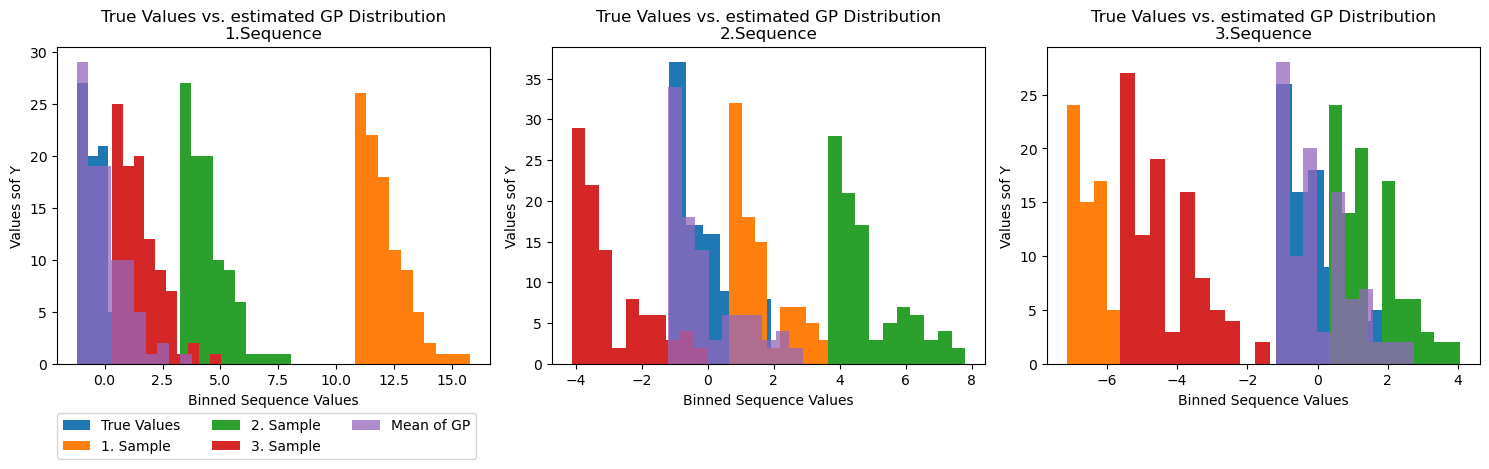

In [ ]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(nrows=1,ncols=3,figsize=(15,5))
ax[0].hist(y[0,:].cpu(),label='True Values')
ax[0].hist(output.sample()[0,:].cpu(),label='1. Sample')
ax[0].hist(output.sample()[0,:].cpu(),label='2. Sample')
ax[0].hist(output.sample()[0,:].cpu(),label='3. Sample')
ax[0].hist(output.mean.cpu().detach().numpy()[0,:],label='Mean of GP',alpha=0.75)
ax[0].set_title('True Values vs. estimated GP Distribution\n1.Sequence')
ax[0].set_xlabel('Binned Sequence Values')
ax[0].set_ylabel('Values sof Y')
ax[0].legend(ncols=3,mode='expand',loc=[0.0,-0.30])

ax[1].hist(y[1,:].cpu(),label='True Values')
ax[1].hist(output.sample()[1,:].cpu(),label='1. Sample')
ax[1].hist(output.sample()[1,:].cpu(),label='2. Sample')
ax[1].hist(output.sample()[1,:].cpu(),label='3. Sample')
ax[1].hist(output.mean.cpu().detach().numpy()[1,:],label='Mean of GP',alpha=0.75)
ax[1].set_title('True Values vs. estimated GP Distribution\n2.Sequence')
ax[1].set_xlabel('Binned Sequence Values')
ax[1].set_ylabel('Values sof Y')

ax[2].hist(y[2,:].cpu(),label='True Values')
ax[2].hist(output.sample()[2,:].cpu(),label='1. Sample')
ax[2].hist(output.sample()[2,:].cpu(),label='2. Sample')
ax[2].hist(output.sample()[2,:].cpu(),label='3. Sample')
ax[2].hist(output.mean.cpu().detach().numpy()[2,:],label='Mean of GP',alpha=0.75)
ax[2].set_title('True Values vs. estimated GP Distribution\n3.Sequence')
ax[2].set_xlabel('Binned Sequence Values')
ax[2].set_ylabel('Values sof Y')

fig.tight_layout()
plt.show()
plt.close()



### **4. Multi-task Learning with neural GPs**

Check out the code for multi-task learning with GPytorch:https://docs.gpytorch.ai/en/v1.13/examples/03_Multitask_Exact_GPs/Multitask_GP_Regression.html. Both groups tasked with the implementation of neural GPs should generate global/multi-output forecasts. One way of doing it is by following the code under the provided link. Alternatively, one could encode this manually by returning multiple MultivariateNormal distributions from the forward method of the GP model. Each distribution could be related to a specific prediction target. How you end up doing it, depends mostly on efficiency. Thus, you might have to test both scenarios.

In [ ]:
#https://pyro.ai/examples/dkl.html